<a href="https://colab.research.google.com/github/ReversePI78/-DevelRocket-AI-game-review-analysis/blob/main/14%EC%B0%A8%EC%8B%9C_%EB%8D%B0%EC%9D%B4%ED%84%B0%ED%92%88%EC%A7%88%EA%B2%80%EC%A6%9D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 14차시: 중간 점검 - 데이터 품질 검증

## 학습 목표
- 수집·전처리된 데이터의 품질을 검증하는 방법을 익힌다
- 데이터 품질 지표를 정의하고 측정할 수 있다
- 데이터 명세서를 작성할 수 있다

## 이 프로젝트에서 할 일
1. 지금까지 작업한 데이터 불러오기
2. 품질 검증: 완전성, 일관성, 정확성 체크
3. 품질 지표 계산 및 시각화
4. 데이터 품질 리포트 생성

---

## 1. 환경 설정

먼저 필요한 라이브러리를 불러옵니다.

In [1]:
# 필요한 라이브러리 설치 (Colab에서 실행 시)
# !pip install pandas matplotlib seaborn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

# 한글 폰트 설정 (Colab)
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False

print("라이브러리 로드 완료!")

라이브러리 로드 완료!


## 2. 데이터 불러오기

이전 차시에서 수집하고 전처리한 리뷰 데이터를 불러옵니다.

**참고**: 실제 데이터 파일 경로는 여러분의 환경에 맞게 수정하세요.

In [2]:
# 데이터 불러오기
# 방법 1: 로컬 파일
# df = pd.read_csv('reviews_preprocessed.csv')

# 방법 2: Google Drive (Colab)
# from google.colab import drive
# drive.mount('/content/drive')
# df = pd.read_csv('/content/drive/MyDrive/reviews_preprocessed.csv')

# 예시: 샘플 데이터 생성 (실습용)
# 실제 프로젝트에서는 위의 방법으로 실제 데이터를 불러오세요
sample_data = {
    'review_id': range(1, 101),
    'review_text': ['게임이 정말 재미있어요! 강추합니다.' if i % 3 == 0
                    else '그저 그래요...' if i % 3 == 1
                    else '' if i % 20 == 0  # 일부러 빈 값 넣기
                    else '버그가 너무 많아서 플레이하기 힘들어요'
                    for i in range(1, 101)],
    'review_text_clean': ['게임 정말 재미있 강추' if i % 3 == 0
                          else '그저 그래' if i % 3 == 1
                          else None if i % 20 == 0
                          else '버그 너무 많 플레이 힘들'
                          for i in range(1, 101)],
    'voted_up': [True if i % 3 == 0 else False if i % 3 == 2 else True for i in range(1, 101)],
    'playtime_forever': [np.random.randint(0, 5000) if i % 15 != 0 else -1 for i in range(1, 101)],  # 일부 이상치
    'timestamp_created': [1700000000 + i * 86400 for i in range(100)],
    'language': ['korean'] * 95 + ['english'] * 5,
    'word_count': [len(str(text).split()) if text else 0 for text in
                   ['게임이 정말 재미있어요! 강추합니다.' if i % 3 == 0
                    else '그저 그래요...' if i % 3 == 1
                    else '' if i % 20 == 0
                    else '버그가 너무 많아서 플레이하기 힘들어요'
                    for i in range(1, 101)]]
}

df = pd.DataFrame(sample_data)
print(f"데이터 로드 완료: {len(df)}개 리뷰")
df.head()

데이터 로드 완료: 100개 리뷰


,review_id,review_text,review_text_clean,voted_up,playtime_forever,timestamp_created,language,word_count
0,1,그저 그래요...,그저 그래,True,2182,1700000000,korean,2
1,2,버그가 너무 많아서 플레이하기 힘들어요,버그 너무 많 플레이 힘들,False,2824,1700086400,korean,5
2,3,게임이 정말 재미있어요! 강추합니다.,게임 정말 재미있 강추,True,56,1700172800,korean,4
3,4,그저 그래요...,그저 그래,True,3885,1700259200,korean,2
4,5,버그가 너무 많아서 플레이하기 힘들어요,버그 너무 많 플레이 힘들,False,937,1700345600,korean,5


## 2-1. 실제 데이터 준비 (8·11차시 재실행)

위 셀은 실습용 샘플 100건입니다. 과제는 **내가 수집한 실제 리뷰**에 품질 검증을 적용하는 것이므로, 8·11차시와 같은 방법으로 데이터를 다시 만듭니다.
(11차시 정제 CSV는 Colab 런타임에만 있었고 런타임이 종료되어 사라졌기 때문입니다.)

1. **8차시와 같은 방법으로 수집**: 스타듀 밸리(413150) 한국어 리뷰 전체를 `steamreviews`로 수집 → `Stardew_Valley_reviews_{날짜}.csv`
   - 작성자 정보(Steam ID·닉네임)는 저장하지 않고 플레이 시간만 사용합니다.
2. **11차시 한국어 파이프라인 적용**: URL 제거 → 공백 제거 → 소문자 → 특수문자 제거(한글 유지) → 연속 문자 제거 → 공백 재정리, 빈 리뷰 제거 → `Stardew_Valley_reviews_processed.csv`
3. 이 노트북의 컬럼 이름(`review_text_clean`, `voted_up`, `playtime_forever`, `timestamp_created`, `word_count`)에 맞춰 `df`를 실제 데이터로 바꿉니다. 이후 원본 셀은 **코드 수정 없이** 실제 데이터로 실행됩니다.

In [3]:
# 수집 라이브러리와 한글 그래프 폰트 설치
!pip install -q steamreviews koreanize-matplotlib
import koreanize_matplotlib
print("설치 완료!")

설치 완료!


In [4]:
# 8차시와 같은 조건으로 스타듀 밸리 한국어 리뷰 전체 수집 (150회 요청마다 310초 대기 → 10~20분 소요)
import steamreviews

MY_GAME_ID = '413150'
MY_GAME_NAME = 'Stardew Valley'
review_dict, query_count = steamreviews.download_reviews_for_app_id(
    MY_GAME_ID,
    chosen_request_params={'language': 'korean'}
)
print(f"수집 완료: {len(review_dict['reviews'])}개 리뷰, API 요청 {query_count}회")

[appID = 413150] expected #reviews = 36221
Number of queries 150 reached. Cooldown: 310 seconds
Number of queries 150 reached. Cooldown: 310 seconds
수집 완료: 36216개 리뷰, API 요청 64회


In [5]:
# 8차시와 같은 컬럼으로 DataFrame 변환 후 CSV 저장 (작성자 정보는 플레이 시간만 사용)
raw = pd.DataFrame([{
    'review_id': rid,
    'review_text': d['review'],
    'recommended': d['voted_up'],
    'playtime_hours': round(d['author']['playtime_forever'] / 60, 1),
    'helpful_votes': d['votes_up'],
    'funny_votes': d['votes_funny'],
    'posted_date': datetime.fromtimestamp(d['timestamp_created']).strftime('%Y-%m-%d'),
    'language': d['language'],
} for rid, d in review_dict['reviews'].items()])

raw_file = f"{MY_GAME_NAME.replace(' ', '_')}_reviews_{datetime.now().strftime('%Y%m%d')}.csv"
raw.to_csv(raw_file, index=False, encoding='utf-8-sig')
print(f"저장 완료: {raw_file} / {len(raw)}개 리뷰, 컬럼 {raw.columns.tolist()}")

저장 완료: Stardew_Valley_reviews_20261123.csv / 36216개 리뷰, 컬럼 ['review_id', 'review_text', 'recommended', 'playtime_hours', 'helpful_votes', 'funny_votes', 'posted_date', 'language']


In [6]:
# 11차시 한국어 전처리 파이프라인(6단계) 재적용
import re

def remove_urls(text): return re.sub(r'https?://\S+', '', text)
def remove_extra_whitespace(text): return re.sub(r'\s+', ' ', text.strip())
def to_lowercase(text): return text.lower()
def remove_special_chars_ko(text): return re.sub(r'[^가-힣ㄱ-ㅎㅏ-ㅣa-zA-Z0-9\s]', ' ', text)
def remove_repeated_chars(text, max_repeat=2): return re.sub(r'(.)\1{' + str(max_repeat) + r',}', r'\1' * max_repeat, text)

steps_ko = [remove_urls, remove_extra_whitespace, to_lowercase, remove_special_chars_ko, remove_repeated_chars, remove_extra_whitespace]
def preprocess_ko(text):
    for step in steps_ko:
        text = step(text)
    return text

mine = pd.read_csv(raw_file)
print('불러온 리뷰 수:', len(mine), '/ review_text 결측:', mine['review_text'].isnull().sum())
mine['review_text'] = mine['review_text'].fillna('').astype(str)
mine['review_processed'] = mine['review_text'].apply(preprocess_ko)
mine_clean = mine[mine['review_processed'].str.len() >= 1]
mine_clean.to_csv('Stardew_Valley_reviews_processed.csv', index=False, encoding='utf-8-sig')
print(f"전처리 후 빈 리뷰 {len(mine) - len(mine_clean)}개 제거 → 저장 완료: Stardew_Valley_reviews_processed.csv / {len(mine_clean)}개")

불러온 리뷰 수: 36216 / review_text 결측: 104
전처리 후 빈 리뷰 819개 제거 → 저장 완료: Stardew_Valley_reviews_processed.csv / 35397개


In [7]:
# 정제 CSV를 불러와 이 노트북의 컬럼 이름에 맞춘 df로 교체
proc = pd.read_csv('Stardew_Valley_reviews_processed.csv')
df = pd.DataFrame({
    'review_id': proc['review_id'],
    'review_text': proc['review_text'],
    'review_text_clean': proc['review_processed'],
    'voted_up': proc['recommended'],
    'playtime_forever': (proc['playtime_hours'] * 60).round().astype(int),   # 분 단위 (Steam 원래 단위)
    'timestamp_created': (pd.to_datetime(proc['posted_date']) - pd.Timestamp('1970-01-01')) // pd.Timedelta('1s'),
    'language': proc['language'],
    'word_count': proc['review_text'].fillna('').astype(str).str.split().str.len(),
})
print(f"실제 데이터로 교체 완료: {len(df):,}개 리뷰 (샘플 100건 대신 사용)")
df[['review_text_clean', 'voted_up', 'playtime_forever', 'language', 'word_count']].head()

실제 데이터로 교체 완료: 35,397개 리뷰 (샘플 100건 대신 사용)


,review_text_clean,voted_up,playtime_forever,language,word_count
0,제가이게임여러번시도해볼려고하기도햇고친구들이랑도여러번조금해봤는데네저한테는좀게임이심심하...,True,798,koreana,1
1,평화로워,True,2082,koreana,1
2,언제 샀는지 기억도 안나는 인생겜 모드 깔고 투자한 시간은 반영되지 않았지만 내 기...,True,44064,koreana,15
3,온갖 더러운 상상과 망상을 온갖 방법으로 즐겨,True,23892,koreana,7
4,레전드 힐링 게임,True,4200,koreana,3


## 3. 품질 검증 1: 완전성 (Completeness)

**완전성**이란 데이터에 빠진 값이 없는지 확인하는 것입니다.

- 결측치(빈 칸)가 얼마나 있는지
- 필수 컬럼에 값이 다 있는지

### 왜 중요할까요?
결측치가 많으면 분석 결과가 왜곡될 수 있습니다. 예를 들어, 부정적인 리뷰만 결측되어 있다면 전체 감성 분석 결과가 긍정으로 치우칠 수 있어요.

In [8]:
# 컬럼별 결측치 확인
print("=" * 50)
print("컬럼별 결측치 현황")
print("=" * 50)

missing_info = pd.DataFrame({
    '결측치 수': df.isnull().sum(),
    '결측치 비율(%)': (df.isnull().sum() / len(df) * 100).round(2)
})

print(missing_info)
print()

# 전체 완전성 점수 계산
total_cells = df.shape[0] * df.shape[1]
missing_cells = df.isnull().sum().sum()
completeness_score = ((total_cells - missing_cells) / total_cells * 100).round(2)

print(f"전체 완전성 점수: {completeness_score}%")

컬럼별 결측치 현황
                   결측치 수  결측치 비율(%)
review_id              0        0.0
review_text            0        0.0
review_text_clean      0        0.0
voted_up               0        0.0
playtime_forever       0        0.0
timestamp_created      0        0.0
language               0        0.0
word_count             0        0.0

전체 완전성 점수: 100.0%


In [9]:
# 빈 문자열도 결측치로 처리해서 확인
print("=" * 50)
print("빈 문자열 포함 결측치 확인 (review_text)")
print("=" * 50)

empty_reviews = df[df['review_text'].str.strip() == ''].shape[0]
null_reviews = df['review_text'].isnull().sum()

print(f"빈 문자열 리뷰: {empty_reviews}개")
print(f"NULL 리뷰: {null_reviews}개")
print(f"실제 사용 가능한 리뷰: {len(df) - empty_reviews - null_reviews}개")

빈 문자열 포함 결측치 확인 (review_text)
빈 문자열 리뷰: 0개
NULL 리뷰: 0개
실제 사용 가능한 리뷰: 35397개


## 4. 품질 검증 2: 일관성 (Consistency)

**일관성**이란 데이터가 논리적으로 맞는지 확인하는 것입니다.

- 플레이 시간이 음수인 경우는 없는지
- 날짜 형식이 일관적인지
- 카테고리 값이 정해진 범위 내에 있는지

### 확인할 규칙들
1. `playtime_forever` >= 0 (음수면 이상)
2. `voted_up`은 True/False만 있어야 함
3. `language`는 정해진 값만 있어야 함

In [10]:
print("=" * 50)
print("일관성 검증 결과")
print("=" * 50)

# 규칙 1: 플레이 시간은 0 이상이어야 함
invalid_playtime = df[df['playtime_forever'] < 0]
print(f"\n[규칙 1] 플레이 시간 < 0: {len(invalid_playtime)}건")
if len(invalid_playtime) > 0:
    print(f"  -> 위반 케이스: {invalid_playtime['playtime_forever'].tolist()[:5]}...")

# 규칙 2: voted_up은 True/False만
valid_votes = df['voted_up'].isin([True, False]).all()
print(f"\n[규칙 2] voted_up 값 유효성: {'통과' if valid_votes else '실패'}")

# 규칙 3: language 값 확인
unique_languages = df['language'].unique()
print(f"\n[규칙 3] language 고유값: {unique_languages}")

# 일관성 점수 계산
consistency_issues = len(invalid_playtime)
consistency_score = ((len(df) - consistency_issues) / len(df) * 100)
print(f"\n일관성 점수: {consistency_score}%")

일관성 검증 결과

[규칙 1] 플레이 시간 < 0: 0건

[규칙 2] voted_up 값 유효성: 통과

[규칙 3] language 고유값: ['koreana']

일관성 점수: 100.0%


## 5. 품질 검증 3: 정확성 (Accuracy)

**정확성**이란 데이터가 현실을 정확하게 반영하는지 확인하는 것입니다.

텍스트 데이터의 경우:
- 원본과 전처리된 텍스트의 의미가 보존되었는지
- 극단적으로 짧거나 긴 리뷰가 있는지 (이상치)
- 전처리 후 내용이 사라진 리뷰는 없는지

In [11]:
print("=" * 50)
print("정확성 검증 결과")
print("=" * 50)

# 단어 수 분포 확인
print("\n[리뷰 길이 통계]")
print(df['word_count'].describe())

# 너무 짧은 리뷰 (1단어 이하)
too_short = df[df['word_count'] <= 1]
print(f"\n너무 짧은 리뷰 (1단어 이하): {len(too_short)}건 ({len(too_short)/len(df)*100:.1f}%)")

# 전처리 후 내용이 사라진 리뷰
lost_content = df[(df['review_text'].str.len() > 0) & (df['review_text_clean'].isnull())]
print(f"전처리 후 손실된 리뷰: {len(lost_content)}건")

정확성 검증 결과

[리뷰 길이 통계]
count    35397.000000
mean         9.736390
std         27.195142
min          1.000000
25%          1.000000
50%          4.000000
75%          9.000000
max       1864.000000
Name: word_count, dtype: float64

너무 짧은 리뷰 (1단어 이하): 9074건 (25.6%)
전처리 후 손실된 리뷰: 0건


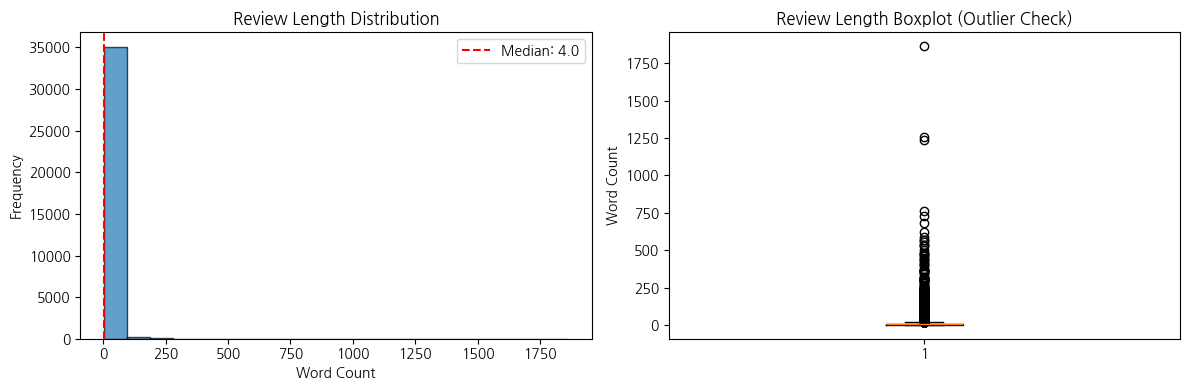

In [12]:
# 리뷰 길이 분포 시각화
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 히스토그램
axes[0].hist(df['word_count'], bins=20, edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Word Count')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Review Length Distribution')
axes[0].axvline(df['word_count'].median(), color='red', linestyle='--', label=f'Median: {df["word_count"].median()}')
axes[0].legend()

# 박스플롯 (이상치 확인)
axes[1].boxplot(df['word_count'])
axes[1].set_ylabel('Word Count')
axes[1].set_title('Review Length Boxplot (Outlier Check)')

plt.tight_layout()
plt.show()

## 6. 샘플링 대표성 검증

13차시에서 배운 샘플링 원칙에 따라, 우리 데이터가 전체를 잘 대표하는지 확인합니다.

- 긍정/부정 리뷰 비율이 극단적으로 치우쳐 있지 않은지
- 특정 시기에만 데이터가 몰려있지 않은지

In [13]:
print("=" * 50)
print("샘플 대표성 검증")
print("=" * 50)

# 긍정/부정 비율
sentiment_dist = df['voted_up'].value_counts(normalize=True) * 100
print("\n[감성 분포]")
print(f"긍정 리뷰: {sentiment_dist.get(True, 0):.1f}%")
print(f"부정 리뷰: {sentiment_dist.get(False, 0):.1f}%")

# 편향 경고
if sentiment_dist.get(True, 0) > 80 or sentiment_dist.get(False, 0) > 80:
    print("\n⚠️ 경고: 감성 분포가 한쪽으로 치우쳐 있습니다!")
    print("   층화 샘플링을 재검토하세요.")
else:
    print("\n✅ 감성 분포가 적절합니다.")

샘플 대표성 검증

[감성 분포]
긍정 리뷰: 98.1%
부정 리뷰: 1.9%

⚠️ 경고: 감성 분포가 한쪽으로 치우쳐 있습니다!
   층화 샘플링을 재검토하세요.



[시간대별 분포]
month
2016-02     13
2016-03    139
2016-04    152
2016-05     50
2016-06     50
          ... 
2026-07    258
2026-08    255
2026-09    167
2026-10    189
2026-11    129
Freq: M, Name: count, Length: 130, dtype: int64


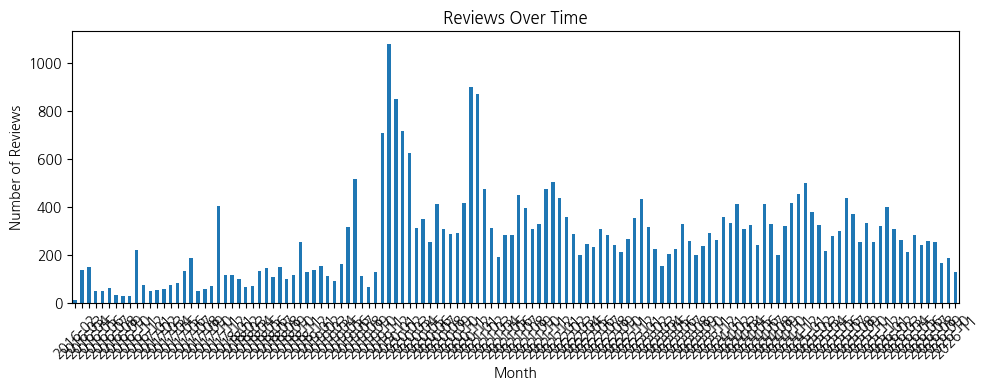

In [14]:
# 시간대별 분포 확인
df['date'] = pd.to_datetime(df['timestamp_created'], unit='s')
df['month'] = df['date'].dt.to_period('M')

print("\n[시간대별 분포]")
time_dist = df['month'].value_counts().sort_index()
print(time_dist)

# 시각화
plt.figure(figsize=(10, 4))
time_dist.plot(kind='bar')
plt.xlabel('Month')
plt.ylabel('Number of Reviews')
plt.title('Reviews Over Time')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 7. 종합 품질 점수 계산

지금까지 확인한 품질 지표를 종합해서 전체 점수를 계산합니다.

In [15]:
# 품질 점수 계산 함수
def calculate_quality_scores(df):
    scores = {}

    # 1. 완전성 (결측치 기반)
    total_cells = df.shape[0] * df.shape[1]
    missing_cells = df.isnull().sum().sum()
    scores['completeness'] = ((total_cells - missing_cells) / total_cells * 100)

    # 2. 일관성 (규칙 위반 기반)
    violations = len(df[df['playtime_forever'] < 0])
    scores['consistency'] = ((len(df) - violations) / len(df) * 100)

    # 3. 정확성 (유효한 리뷰 비율)
    valid_reviews = len(df[(df['word_count'] > 1) & (df['review_text_clean'].notna())])
    scores['accuracy'] = (valid_reviews / len(df) * 100)

    # 4. 대표성 (균형 점수 - 50:50에 가까울수록 높음)
    pos_ratio = df['voted_up'].mean()
    balance = 1 - abs(pos_ratio - 0.5) * 2  # 0.5일 때 1, 0이나 1일 때 0
    scores['representativeness'] = balance * 100

    # 종합 점수 (가중 평균)
    weights = {'completeness': 0.3, 'consistency': 0.25, 'accuracy': 0.25, 'representativeness': 0.2}
    scores['overall'] = sum(scores[k] * weights[k] for k in weights.keys())

    return {k: round(v, 1) for k, v in scores.items()}

# 점수 계산
quality_scores = calculate_quality_scores(df)

print("=" * 50)
print("📊 데이터 품질 종합 점수")
print("=" * 50)
for metric, score in quality_scores.items():
    if metric != 'overall':
        status = '✅' if score >= 80 else '⚠️' if score >= 60 else '❌'
        print(f"{status} {metric}: {score}%")

print("="*50)
overall_status = '✅ 우수' if quality_scores['overall'] >= 80 else '⚠️ 보통' if quality_scores['overall'] >= 60 else '❌ 개선필요'
print(f"🎯 종합 점수: {quality_scores['overall']}% ({overall_status})")

📊 데이터 품질 종합 점수
✅ completeness: 100.0%
✅ consistency: 100.0%
⚠️ accuracy: 74.4%
❌ representativeness: 3.8%
🎯 종합 점수: 74.4% (⚠️ 보통)


## 8. 데이터 품질 리포트 생성

지금까지의 분석 결과를 정리해서 리포트를 생성합니다.

이 리포트는 다음 차시에서 LLM 분석을 시작하기 전에 데이터 상태를 문서화하는 역할을 합니다.

In [16]:
# 리포트 생성
report_date = datetime.now().strftime('%Y-%m-%d %H:%M')

report = f"""
================================================================================
                         데이터 품질 검증 리포트
================================================================================

생성일시: {report_date}
데이터셋: Steam 게임 리뷰
총 레코드 수: {len(df):,}건

--------------------------------------------------------------------------------
1. 기본 정보
--------------------------------------------------------------------------------
- 컬럼 수: {df.shape[1]}개
- 컬럼 목록: {', '.join(df.columns.tolist())}
- 데이터 기간: {df['date'].min().strftime('%Y-%m-%d')} ~ {df['date'].max().strftime('%Y-%m-%d')}

--------------------------------------------------------------------------------
2. 품질 점수 요약
--------------------------------------------------------------------------------
- 완전성 (Completeness): {quality_scores['completeness']}%
- 일관성 (Consistency): {quality_scores['consistency']}%
- 정확성 (Accuracy): {quality_scores['accuracy']}%
- 대표성 (Representativeness): {quality_scores['representativeness']}%
- 종합 점수: {quality_scores['overall']}%

--------------------------------------------------------------------------------
3. 결측치 현황
--------------------------------------------------------------------------------
{missing_info.to_string()}

--------------------------------------------------------------------------------
4. 감성 분포
--------------------------------------------------------------------------------
- 긍정 리뷰: {df['voted_up'].sum():,}건 ({df['voted_up'].mean()*100:.1f}%)
- 부정 리뷰: {(~df['voted_up']).sum():,}건 ({(1-df['voted_up'].mean())*100:.1f}%)

--------------------------------------------------------------------------------
5. 발견된 이슈 및 권장 조치
--------------------------------------------------------------------------------
"""

# 이슈 추가
issues = []
if quality_scores['completeness'] < 95:
    issues.append("- 결측치가 있습니다. 원인을 파악하고 적절히 처리하세요.")
if quality_scores['consistency'] < 100:
    issues.append("- 일관성 위반 데이터가 있습니다. 이상치를 확인하세요.")
if quality_scores['accuracy'] < 90:
    issues.append("- 너무 짧은 리뷰가 많습니다. 필터링을 고려하세요.")
if quality_scores['representativeness'] < 70:
    issues.append("- 감성 분포가 편향되어 있습니다. 층화 샘플링을 재검토하세요.")

if issues:
    report += "\n".join(issues)
else:
    report += "특별한 이슈가 발견되지 않았습니다."

report += """

--------------------------------------------------------------------------------
6. 다음 단계
--------------------------------------------------------------------------------
이 데이터셋은 LLM 분석을 위한 기본 품질 요건을 충족합니다.
15차시 'LLM API 연동 기초'에서 이 데이터를 활용해 분석을 시작합니다.

================================================================================
"""

print(report)


                         데이터 품질 검증 리포트

생성일시: 2026-11-23 03:26
데이터셋: Steam 게임 리뷰
총 레코드 수: 35,397건

--------------------------------------------------------------------------------
1. 기본 정보
--------------------------------------------------------------------------------
- 컬럼 수: 10개
- 컬럼 목록: review_id, review_text, review_text_clean, voted_up, playtime_forever, timestamp_created, language, word_count, date, month
- 데이터 기간: 2016-02-27 ~ 2026-11-22

--------------------------------------------------------------------------------
2. 품질 점수 요약
--------------------------------------------------------------------------------
- 완전성 (Completeness): 100.0%
- 일관성 (Consistency): 100.0%
- 정확성 (Accuracy): 74.4%
- 대표성 (Representativeness): 3.8%
- 종합 점수: 74.4%

--------------------------------------------------------------------------------
3. 결측치 현황
--------------------------------------------------------------------------------
                   결측치 수  결측치 비율(%)
review_id              0        0.0
r

In [17]:
# 리포트 파일로 저장
with open('data_quality_report.txt', 'w', encoding='utf-8') as f:
    f.write(report)

print("✅ 리포트가 'data_quality_report.txt' 파일로 저장되었습니다.")

✅ 리포트가 'data_quality_report.txt' 파일로 저장되었습니다.


## 9. 데이터 명세서 작성

마지막으로, 이 데이터셋의 명세서를 작성합니다.

데이터 명세서는 데이터의 "설명서"입니다. 나중에 이 데이터를 다시 사용하거나, 다른 사람이 사용할 때 꼭 필요합니다.

In [18]:
# 데이터 명세서 생성
spec = {
    '데이터셋명': 'Steam 게임 리뷰 데이터',
    '생성일': report_date,
    '레코드수': len(df),
    '컬럼수': df.shape[1],
    '용량': f"{df.memory_usage(deep=True).sum() / 1024:.1f} KB",
    '품질점수': f"{quality_scores['overall']}%",
    '컬럼정보': {}
}

# 각 컬럼 정보
for col in df.columns:
    spec['컬럼정보'][col] = {
        '데이터타입': str(df[col].dtype),
        '결측치수': int(df[col].isnull().sum()),
        '고유값수': int(df[col].nunique()),
        '샘플값': str(df[col].dropna().iloc[0])[:50] if len(df[col].dropna()) > 0 else 'N/A'
    }

# 명세서 출력
print("=" * 50)
print("📋 데이터 명세서")
print("=" * 50)
for key, value in spec.items():
    if key != '컬럼정보':
        print(f"{key}: {value}")

print("\n[컬럼 상세 정보]")
for col, info in spec['컬럼정보'].items():
    print(f"\n  {col}:")
    for k, v in info.items():
        print(f"    - {k}: {v}")

📋 데이터 명세서
데이터셋명: Steam 게임 리뷰 데이터
생성일: 2026-11-23 03:26
레코드수: 35397
컬럼수: 10
용량: 13678.9 KB
품질점수: 74.4%

[컬럼 상세 정보]

  review_id:
    - 데이터타입: int64
    - 결측치수: 0
    - 고유값수: 35397
    - 샘플값: 240797773

  review_text:
    - 데이터타입: object
    - 결측치수: 0
    - 고유값수: 29204
    - 샘플값: 제가이게임여러번시도해볼려고하기도햇고친구들이랑도여러번조금해봤는데네저한테는좀게임이심심하네요스듀

  review_text_clean:
    - 데이터타입: object
    - 결측치수: 0
    - 고유값수: 27819
    - 샘플값: 제가이게임여러번시도해볼려고하기도햇고친구들이랑도여러번조금해봤는데네저한테는좀게임이심심하네요스듀

  voted_up:
    - 데이터타입: bool
    - 결측치수: 0
    - 고유값수: 2
    - 샘플값: True

  playtime_forever:
    - 데이터타입: int64
    - 결측치수: 0
    - 고유값수: 7964
    - 샘플값: 798

  timestamp_created:
    - 데이터타입: int64
    - 결측치수: 0
    - 고유값수: 3778
    - 샘플값: 1795305600

  language:
    - 데이터타입: object
    - 결측치수: 0
    - 고유값수: 1
    - 샘플값: koreana

  word_count:
    - 데이터타입: int64
    - 결측치수: 0
    - 고유값수: 260
    - 샘플값: 1

  date:
    - 데이터타입: datetime64[ns]
    - 결측치수: 0
    - 고유값수: 3778
    - 샘플값: 2026-11-22 00:00:00

  month:
    - 데이터타입: 

## 10. 과제 기준 보강 (LMS 과제 안내 기준)

위 원본 코드는 샘플 데이터용이라 과제 안내의 기준과 몇 가지가 다릅니다. 같은 데이터에 과제 기준을 적용해 다시 계산합니다.

| 지표 | 원본 노트북 계산 | 과제 안내 기준 (이 섹션) |
|---|---|---|
| 완전성 | 전체 셀 중 결측 셀 비율 | 100% − 컬럼별 평균 결측률 (빈 문자열도 결측으로 셈) |
| 일관성 | 규칙 1개(플레이 시간 음수)만 위반 건수 계산 | 규칙 5개, 하나라도 위반한 행 비율 |
| 정확도 | 1단어 이하 리뷰 비율 | **IQR 방식** 이상치(플레이 시간·리뷰 길이) + 1글자 리뷰 |
| 대표성 | 50:50에 가까울수록 높음 | 같은 계산 + 90/10 편향 판정, 시기 집중도 확인 |

In [19]:
# [완전성] 100% - 컬럼별 평균 결측률 (텍스트 컬럼은 빈 문자열/공백만 있는 값도 결측으로 셈)
base_cols = ['review_id', 'review_text', 'review_text_clean', 'voted_up', 'playtime_forever', 'timestamp_created', 'language', 'word_count']
def is_missing(s): return s.isnull() | (s.astype(str).str.strip() == '') if (s.dtype == object or pd.api.types.is_string_dtype(s)) else s.isnull()

missing_rate = pd.Series({c: is_missing(df[c]).mean() * 100 for c in base_cols}).round(3)
completeness_v2 = round(100 - missing_rate.mean(), 1)
print("컬럼별 결측률(%):")
print(missing_rate.to_string())
print(f"\n완전성 점수 = 100 - 평균 결측률 {missing_rate.mean():.3f}% = {completeness_v2}%")
if df['review_text_clean'].isnull().any():
    print("\n결측으로 읽힌 정제 리뷰의 원문:", df.loc[df['review_text_clean'].isnull(), 'review_text'].head(10).tolist())

컬럼별 결측률(%):
review_id            0.0
review_text          0.0
review_text_clean    0.0
voted_up             0.0
playtime_forever     0.0
timestamp_created    0.0
language             0.0
word_count           0.0

완전성 점수 = 100 - 평균 결측률 0.000% = 100.0%


In [20]:
# [일관성] 규칙 5개 위반 건수와, 하나라도 위반한 행 비율
rules = {
    '1. 리뷰 원문이 비어 있으면 안 됨': is_missing(df['review_text']),
    '2. 플레이 시간은 0 이상': df['playtime_forever'] < 0,
    '3. 추천 여부는 True/False만': ~df['voted_up'].isin([True, False]),
    "4. 언어는 'koreana'(수집 조건)만": df['language'] != 'koreana',
    '5. 리뷰 ID는 중복되면 안 됨': df['review_id'].duplicated(keep=False),
}
violation_table = pd.DataFrame({'위반 건수': {k: int(v.sum()) for k, v in rules.items()},
                                '위반 비율(%)': {k: round(v.mean() * 100, 3) for k, v in rules.items()}})
any_violation = pd.concat(rules.values(), axis=1).any(axis=1)
consistency_v2 = round(100 - any_violation.mean() * 100, 1)
print(violation_table.to_string())
print(f"\n하나라도 위반한 행: {any_violation.sum()}건 → 일관성 점수 {consistency_v2}%")
print("language 실제 값:", df['language'].value_counts().to_dict())

                          위반 건수  위반 비율(%)
1. 리뷰 원문이 비어 있으면 안 됨          0       0.0
2. 플레이 시간은 0 이상               0       0.0
3. 추천 여부는 True/False만         0       0.0
4. 언어는 'koreana'(수집 조건)만      0       0.0
5. 리뷰 ID는 중복되면 안 됨            0       0.0

하나라도 위반한 행: 0건 → 일관성 점수 100.0%
language 실제 값: {'koreana': 35397}


In [21]:
# [정확도] IQR 방식 이상치 탐지: 플레이 시간(시간), 리뷰 길이(글자 수) + 1글자 리뷰
def iqr_bounds(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    return q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)

df['playtime_h'] = df['playtime_forever'] / 60
df['char_len'] = df['review_text_clean'].fillna('').astype(str).str.len()
outlier_info = {}
for col, label in [('playtime_h', '플레이 시간(시간)'), ('char_len', '리뷰 길이(글자)')]:
    lo, hi = iqr_bounds(df[col])
    mask = (df[col] < lo) | (df[col] > hi)
    outlier_info[label] = mask
    print(f"{label}: Q1={df[col].quantile(0.25):.1f}, Q3={df[col].quantile(0.75):.1f}, 정상 범위 {max(lo, 0):.1f} ~ {hi:.1f} → 이상치 {mask.sum():,}건 ({mask.mean()*100:.1f}%), 최댓값 {df[col].max():,.1f}")
outlier_info['1글자 리뷰'] = df['char_len'] <= 1
print(f"1글자 리뷰: {outlier_info['1글자 리뷰'].sum()}건, 예시 {df.loc[outlier_info['1글자 리뷰'], 'review_text_clean'].value_counts().head(5).to_dict()}")

any_outlier = pd.concat(outlier_info.values(), axis=1).any(axis=1)
accuracy_v2 = round(100 - any_outlier.mean() * 100, 1)
print(f"\n이상치가 하나라도 있는 행: {any_outlier.sum():,}건 → 정확도 점수 {accuracy_v2}%")

플레이 시간(시간): Q1=76.4, Q3=314.8, 정상 범위 0.0 ~ 672.4 → 이상치 2,392건 (6.8%), 최댓값 10,563.4
리뷰 길이(글자): Q1=5.0, Q3=37.0, 정상 범위 0.0 ~ 85.0 → 이상치 3,521건 (9.9%), 최댓값 7,230.0
1글자 리뷰: 1135건, 예시 {'굿': 420, '굳': 168, 'd': 81, '짱': 54, 'b': 36}

이상치가 하나라도 있는 행: 6,696건 → 정확도 점수 81.1%


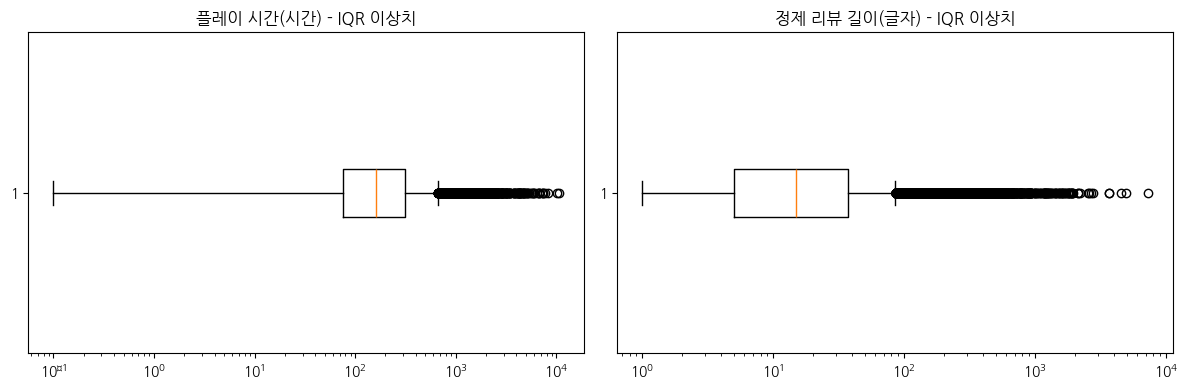

In [22]:
# IQR 이상치 시각화 (박스플롯)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].boxplot(df['playtime_h'], vert=False)
axes[0].set_title('플레이 시간(시간) - IQR 이상치')
axes[0].set_xscale('log')
axes[1].boxplot(df['char_len'], vert=False)
axes[1].set_title('정제 리뷰 길이(글자) - IQR 이상치')
axes[1].set_xscale('log')
plt.tight_layout()
plt.show()

추천 98.1% / 비추천 1.9% → 균형 점수 3.8%
판정: ⚠️ 90/10 이상 → 긍정 편향 의심 (해석 시 주의)

연도별 리뷰 수: {2016: 862, 2017: 1358, 2018: 1511, 2019: 3605, 2020: 5741, 2021: 4897, 2022: 3444, 2023: 3153, 2024: 4126, 2025: 3983, 2026: 2717}
가장 많은 연도 비중: 16.2% (2020년)
연도별 추천 비율(%): {2016: 98.4, 2017: 97.6, 2018: 97.1, 2019: 98.3, 2020: 98.3, 2021: 97.9, 2022: 97.5, 2023: 98.4, 2024: 98.4, 2025: 98.3, 2026: 97.9}


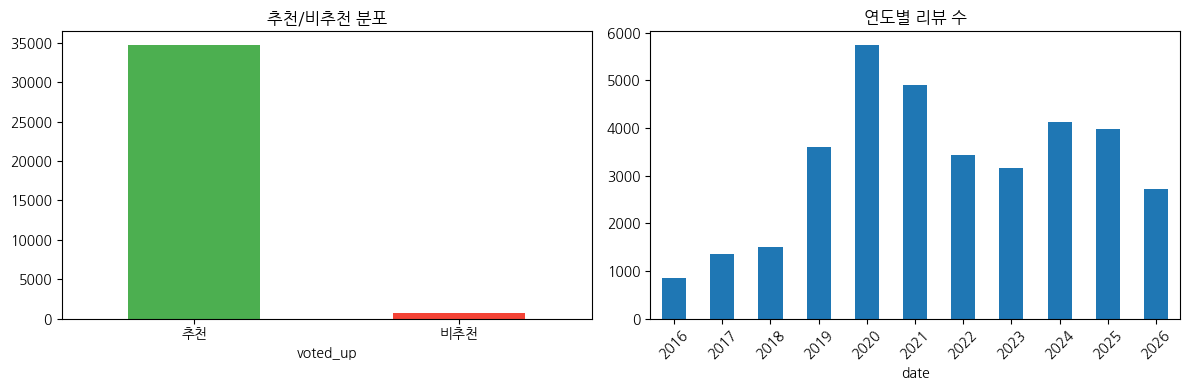

In [23]:
# [대표성] 추천 비율 균형 점수(원본 계산과 동일) + 90/10 편향 판정 + 시기 집중도
pos_ratio = df['voted_up'].mean()
representativeness_v2 = round((1 - abs(pos_ratio - 0.5) * 2) * 100, 1)
print(f"추천 {pos_ratio*100:.1f}% / 비추천 {(1-pos_ratio)*100:.1f}% → 균형 점수 {representativeness_v2}%")
print("판정:", "⚠️ 90/10 이상 → 긍정 편향 의심 (해석 시 주의)" if max(pos_ratio, 1 - pos_ratio) >= 0.9 else "✅ 편향 아님")

years = df['date'].dt.year.value_counts().sort_index()
print("\n연도별 리뷰 수:", years.to_dict())
print(f"가장 많은 연도 비중: {years.max() / len(df) * 100:.1f}% ({years.idxmax()}년)")
print("연도별 추천 비율(%):", (df.groupby(df['date'].dt.year)['voted_up'].mean() * 100).round(1).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df['voted_up'].map({True: '추천', False: '비추천'}).value_counts().plot(kind='bar', ax=axes[0], color=['#4CAF50', '#f44336'], rot=0)
axes[0].set_title('추천/비추천 분포')
years.plot(kind='bar', ax=axes[1], rot=45)
axes[1].set_title('연도별 리뷰 수')
plt.tight_layout()
plt.show()

     원본 노트북 계산  과제 기준 계산   가중치
완전성      100.0     100.0  0.30
일관성      100.0     100.0  0.25
정확도       74.4      81.1  0.25
대표성        3.8       3.8  0.20
종합        74.4      76.0  1.00

🎯 과제 기준 종합 점수: 76.0% → 양호 (가벼운 전처리 후 분석) / 통과 기준 60% 충족 ✅


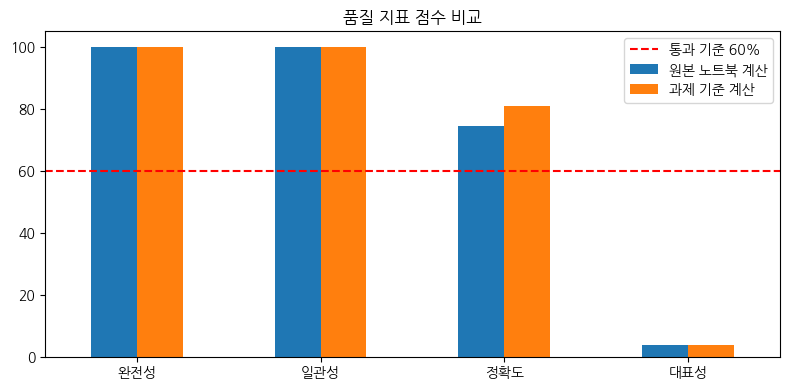

In [24]:
# [종합] 가중치 0.3 / 0.25 / 0.25 / 0.2, 등급은 과제 안내 Step 6 기준
weights = {'완전성': 0.3, '일관성': 0.25, '정확도': 0.25, '대표성': 0.2}
v2 = {'완전성': completeness_v2, '일관성': consistency_v2, '정확도': accuracy_v2, '대표성': representativeness_v2}
overall_v2 = round(sum(v2[k] * w for k, w in weights.items()), 1)
def grade(x): return '우수 (바로 분석 가능)' if x >= 90 else '양호 (가벼운 전처리 후 분석)' if x >= 70 else '보통 (품질 이슈 해결 필요)' if x >= 50 else '미흡 (재수집 검토)'

score_table = pd.DataFrame({
    '원본 노트북 계산': [quality_scores['completeness'], quality_scores['consistency'], quality_scores['accuracy'], quality_scores['representativeness'], quality_scores['overall']],
    '과제 기준 계산': [*v2.values(), overall_v2],
    '가중치': [*weights.values(), 1.0],
}, index=[*weights.keys(), '종합'])
print(score_table.to_string())
print(f"\n🎯 과제 기준 종합 점수: {overall_v2}% → {grade(overall_v2)} / 통과 기준 60% {'충족 ✅' if overall_v2 >= 60 else '미달 ❌'}")

ax = score_table.loc[list(weights), ['원본 노트북 계산', '과제 기준 계산']].plot(kind='bar', rot=0, figsize=(8, 4), ylim=(0, 105))
ax.axhline(60, color='red', linestyle='--', label='통과 기준 60%')
ax.set_title('품질 지표 점수 비교')
ax.legend()
plt.tight_layout()
plt.show()

In [28]:
# [개선 실험] 일관성 위반·결측·1글자 리뷰를 제거하면 점수가 어떻게 바뀌나 (긴 리뷰·고수 플레이어는 정상 데이터라 남김)
df_fixed = df[~any_violation & ~outlier_info['1글자 리뷰'] & df['review_text_clean'].notna()].copy()
pos_fixed = df_fixed['voted_up'].mean()
fixed = {'완전성': round(100 - pd.Series({c: is_missing(df_fixed[c]).mean() * 100 for c in base_cols}).mean(), 1),
         '일관성': 100.0,
         '정확도': round(100 - any_outlier[df_fixed.index].mean() * 100, 1),
         '대표성': round((1 - abs(pos_fixed - 0.5) * 2) * 100, 1)}
overall_fixed = round(sum(fixed[k] * w for k, w in weights.items()), 1)
print(f"정제 전 {len(df):,}건 → 정제 후 {len(df_fixed):,}건 (제거 {len(df) - len(df_fixed):,}건)")
print("정제 후 지표:", {k: float(v) for k, v in fixed.items()}, f"→ 종합 {overall_fixed}%")
print("\n대표성은 데이터를 지워서는 올라가지 않음 → 게임 자체가 호평 위주(실제 평가 반영)이므로 편향을 '오류'가 아닌 '해석 시 주의점'으로 기록")

정제 전 35,397건 → 정제 후 34,262건 (제거 1,135건)
정제 후 지표: {'완전성': 100.0, '일관성': 100.0, '정확도': 83.8, '대표성': 3.8} → 종합 76.7%

대표성은 데이터를 지워서는 올라가지 않음 → 게임 자체가 호평 위주(실제 평가 반영)이므로 편향을 '오류'가 아닌 '해석 시 주의점'으로 기록


In [29]:
# 데이터 품질 검증 리포트 (과제 기준) 생성 및 저장
issues_v2 = []
if missing_rate.max() > 0: issues_v2.append(f"- 결측: 가장 높은 컬럼 {missing_rate.idxmax()} {missing_rate.max():.2f}% → 결측 행 제거 (분석 대상에서 제외)")
for k, v in rules.items():
    if v.sum() > 0: issues_v2.append(f"- 일관성 위반 [{k}]: {v.sum()}건 → 해당 행 제거 또는 수집 조건 재확인")
for k, v in outlier_info.items():
    if v.sum() > 0: issues_v2.append(f"- 이상치 [{k}]: {v.sum():,}건 ({v.mean()*100:.1f}%) → " + {'1글자 리뷰': "정제 실험에서 제거 (단, '굿'·'굳'은 긍정 의미가 분명해 LLM 감성 분석에는 남겨도 됨)", '플레이 시간(시간)': '수천 시간 플레이어는 실제로 존재하므로 유지, 플레이 시간 비교는 평균 대신 중앙값 사용', '리뷰 길이(글자)': '긴 리뷰는 정보가 많아 유지, LLM 분석 시 토큰 한도에 맞춰 길이 제한'}[k])
if max(pos_ratio, 1 - pos_ratio) >= 0.9: issues_v2.append(f"- 대표성: 추천 {pos_ratio*100:.1f}%로 긍정 편향 → 비추천 리뷰를 따로 층화 추출해 부정 의견 분석, 결과 해석 시 편향 명시")

report_v2 = f"""
================================================================================
                 데이터 품질 검증 리포트 (과제 기준, 실제 데이터)
================================================================================
생성일시: {datetime.now().strftime('%Y-%m-%d %H:%M')}
데이터셋: {MY_GAME_NAME} 한국어 Steam 리뷰 (8차시 수집 → 11차시 전처리)
총 레코드 수: {len(df):,}건 / 기간 {df['date'].min():%Y-%m-%d} ~ {df['date'].max():%Y-%m-%d}

[품질 점수]
- 완전성 (Completeness):        {completeness_v2}%  (100 - 평균 결측률)
- 일관성 (Consistency):         {consistency_v2}%  (규칙 5개)
- 정확도 (Accuracy):            {accuracy_v2}%  (IQR 이상치 + 1글자 리뷰)
- 대표성 (Representativeness):  {representativeness_v2}%  (추천 {pos_ratio*100:.1f}%)
- 종합 (0.3/0.25/0.25/0.2):     {overall_v2}%  → {grade(overall_v2)}
- 정제 실험 후 종합:            {overall_fixed}%  ({len(df_fixed):,}건)

[발견된 이슈 및 개선 방안]
""" + "\n".join(issues_v2) + "\n" + "=" * 80

print(report_v2)
with open('data_quality_report_v2.txt', 'w', encoding='utf-8') as f:
    f.write(report_v2)
print("✅ 'data_quality_report_v2.txt' 저장 완료")


                 데이터 품질 검증 리포트 (과제 기준, 실제 데이터)
생성일시: 2026-11-23 03:29
데이터셋: Stardew Valley 한국어 Steam 리뷰 (8차시 수집 → 11차시 전처리)
총 레코드 수: 35,397건 / 기간 2016-02-27 ~ 2026-11-22

[품질 점수]
- 완전성 (Completeness):        100.0%  (100 - 평균 결측률)
- 일관성 (Consistency):         100.0%  (규칙 5개)
- 정확도 (Accuracy):            81.1%  (IQR 이상치 + 1글자 리뷰)
- 대표성 (Representativeness):  3.8%  (추천 98.1%)
- 종합 (0.3/0.25/0.25/0.2):     76.0%  → 양호 (가벼운 전처리 후 분석)
- 정제 실험 후 종합:            76.7%  (34,262건)

[발견된 이슈 및 개선 방안]
- 이상치 [플레이 시간(시간)]: 2,392건 (6.8%) → 수천 시간 플레이어는 실제로 존재하므로 유지, 플레이 시간 비교는 평균 대신 중앙값 사용
- 이상치 [리뷰 길이(글자)]: 3,521건 (9.9%) → 긴 리뷰는 정보가 많아 유지, LLM 분석 시 토큰 한도에 맞춰 길이 제한
- 이상치 [1글자 리뷰]: 1,135건 (3.2%) → 정제 실험에서 제거 (단, '굿'·'굳'은 긍정 의미가 분명해 LLM 감성 분석에는 남겨도 됨)
- 대표성: 추천 98.1%로 긍정 편향 → 비추천 리뷰를 따로 층화 추출해 부정 의견 분석, 결과 해석 시 편향 명시
✅ 'data_quality_report_v2.txt' 저장 완료


In [27]:
# 데이터 명세서 (과제 안내 Step 7 항목: 컬럼명·데이터 타입·결측 수/비율·고유값 수·샘플 값·설명)
desc = {
    'review_id': 'Steam 리뷰 고유 ID', 'review_text': '리뷰 원문', 'review_text_clean': '11차시 한국어 파이프라인 정제 결과',
    'voted_up': '추천 여부 (True=추천)', 'playtime_forever': '작성자 총 플레이 시간(분)', 'timestamp_created': '작성 시각(유닉스 초, 일 단위)',
    'language': "리뷰 언어 (수집 조건 korean → 값 'koreana')", 'word_count': '원문 띄어쓰기 기준 단어 수',
}
spec_table = pd.DataFrame([{
    '컬럼명': c,
    '데이터 타입': str(df[c].dtype),
    '결측 수': int(is_missing(df[c]).sum()),
    '결측 비율(%)': round(is_missing(df[c]).mean() * 100, 3),
    '고유값 수': int(df[c].nunique()),
    '샘플 값': str(df[c].dropna().iloc[0])[:30],
    '설명': desc[c],
} for c in base_cols])
spec_table.to_csv('data_spec.csv', index=False, encoding='utf-8-sig')
print(f"데이터셋: {MY_GAME_NAME} 한국어 리뷰 / {len(df):,}행 × {len(base_cols)}열 / 품질 점수 {overall_v2}%")
spec_table

데이터셋: Stardew Valley 한국어 리뷰 / 35,397행 × 8열 / 품질 점수 76.0%


,컬럼명,데이터 타입,결측 수,결측 비율(%),고유값 수,샘플 값,설명
0,review_id,int64,0,0.0,35397,240797773,Steam 리뷰 고유 ID
1,review_text,object,0,0.0,29204,제가이게임여러번시도해볼려고하기도햇고친구들이랑도여러번조금,리뷰 원문
2,review_text_clean,object,0,0.0,27819,제가이게임여러번시도해볼려고하기도햇고친구들이랑도여러번조금,11차시 한국어 파이프라인 정제 결과
3,voted_up,bool,0,0.0,2,True,추천 여부 (True=추천)
4,playtime_forever,int64,0,0.0,7964,798,작성자 총 플레이 시간(분)
5,timestamp_created,int64,0,0.0,3778,1795305600,"작성 시각(유닉스 초, 일 단위)"
6,language,object,0,0.0,1,koreana,리뷰 언어 (수집 조건 korean → 값 'koreana')
7,word_count,int64,0,0.0,260,1,원문 띄어쓰기 기준 단어 수


## 11. 결과 메모

**[적용 결과]**
- 대상: 스타듀 밸리 한국어 리뷰 36,216건 수집(2026-11-23) → 11차시 파이프라인으로 정제 후 35,397건 (빈 리뷰 819건 제거), 기간 2016-02-27 ~ 2026-11-22
- 과제 기준 품질 점수: 완전성 100.0% / 일관성 100.0% (규칙 5개, 위반 0건) / 정확도 81.1% (IQR 이상치 등 6,696건) / 대표성 3.8% (추천 98.1%)
- **종합 76.0% → 양호(가벼운 전처리 후 분석), 통과 기준 60% 충족**
- 원본 노트북 계산 방식으로는 74.4% (정확도 74.4%: 띄어쓰기 기준 1단어 이하 리뷰 25.6%)
- 정제 실험(1글자 리뷰 1,135건 제거) 후 종합 76.7% (34,262건)
- 산출물: `data_quality_report_v2.txt` (품질 검증 리포트), `data_spec.csv` (데이터 명세서)

**[발견한 점]**
1. **완전성·일관성 100%는 11차시 전처리 덕분**: 원문 결측 104건과 기호만 있는 리뷰가 11차시에서 빈 리뷰(819건)로 걸러져 이 단계에는 결측이 없다. 수집 직후 원본 기준 결측률은 0.29%(104/36,216)다.
2. **한국어에는 '단어 수' 기준이 맞지 않는다**: 원본 노트북은 띄어쓰기로 센 1단어 이하 리뷰를 이상값으로 봐서 25.6%(9,074건)가 걸렸다. 한국어는 '갓겜'은 물론 띄어쓰기 없이 쓴 긴 문장도 1단어가 된다. 글자 수로 보면 1글자 리뷰는 1,135건(3.2%)뿐이다('굿' 420, '굳' 168).
3. **IQR 이상치는 '오류'가 아니라 '드문 값'**: 플레이 시간 상한(672시간)을 넘는 리뷰가 2,392건(최대 10,563시간), 85자를 넘는 긴 리뷰가 3,521건이다. 장기 플레이가 흔한 게임이고 긴 리뷰는 정보가 많아 지우지 않았다. 정확도 81%는 오류율이 아니라 분포의 긴 꼬리를 뜻한다.
4. **대표성은 데이터를 지워도 오르지 않는다**: 추천 98.1%로 90/10 기준을 넘는 긍정 편향이다. 연도별 추천 비율도 97.1~98.4%로 일정해 시기 편향이 아니라 게임 자체의 평가다(리뷰는 2020년이 5,741건, 16.2%로 가장 많음). 비추천은 약 670건(1.9%)뿐이라 부정 의견은 비추천만 따로 뽑아 분석해야 한다.
5. **가중치가 결과를 좌우한다**: 대표성 3.8%가 종합 점수를 약 19점 끌어내린다. 데이터 오류를 보려면 대표성은 따로 보고하고, 감성 분석이 목적이면 대표성 가중치를 높여 편향 경고를 강조하는 편이 낫다.

---

## 프로젝트 완료!

### 이번 차시에서 배운 것
1. **완전성 검증**: 결측치 확인 및 비율 계산
2. **일관성 검증**: 데이터 규칙 위반 체크
3. **정확성 검증**: 이상치 및 손실 데이터 확인
4. **대표성 검증**: 샘플링 편향 체크
5. **품질 리포트 생성**: 문서화